<a href="https://colab.research.google.com/github/sadhanakumble/DemoFirst/blob/main/VG_Face_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:

# Run once in Google Colab; restart runtime if prompted.
%pip -q install insightface onnxruntime scikit-learn opencv-python-headless matplotlib pandas tqdm


In [19]:
from pathlib import Path
import json, platform
import numpy as np
import cv2
import matplotlib.pyplot as plt
import onnxruntime as ort
import sklearn
from tqdm.auto import tqdm
from sklearn.datasets import fetch_lfw_people
from sklearn.metrics import roc_auc_score, roc_curve
from insightface.app import FaceAnalysis

BASE_DIR = Path('/content/ArcFace_LFW') if Path('/content').exists() else Path.cwd() / 'ArcFace_LFW'
EMBED_DIR = BASE_DIR / 'embeddings'
GRAPH_DIR = BASE_DIR / 'graphs'
RESULT_DIR = BASE_DIR / 'results'
for folder in (EMBED_DIR, GRAPH_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Output directory:', BASE_DIR)

Output directory: /content/ArcFace_LFW


In [20]:
# LFW image array is float32; inspect range rather than assuming normalization.
lfw = fetch_lfw_people(min_faces_per_person=10, resize=1.0, color=True, download_if_missing=True)
X, y = lfw.images, lfw.target
print('Images:', len(X), 'Identities:', len(lfw.target_names))
print('Shape:', X.shape, 'dtype:', X.dtype, 'range:', (X.min(), X.max()))

Images: 4324 Identities: 158
Shape: (4324, 125, 94, 3) dtype: float32 range: (np.float32(0.0), np.float32(1.0))


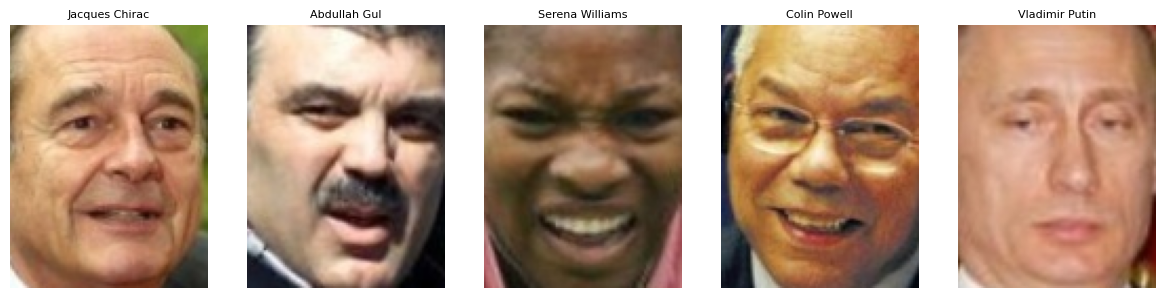

First image: (125, 94, 3) pixel range: (np.uint8(0), np.uint8(255))


In [21]:
def to_rgb_uint8(image):
    img = np.asarray(image)
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    elif img.ndim != 3 or img.shape[2] not in (3, 4):
        raise ValueError(f'Unsupported image shape: {img.shape}')
    if img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_RGBA2RGB)
    if np.issubdtype(img.dtype, np.floating) and img.min() >= 0 and img.max() <= 1.0:
        img = img * 255.0
    return np.clip(img, 0, 255).round().astype(np.uint8)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(to_rgb_uint8(X[i]))
    ax.set_title(str(lfw.target_names[y[i]]), fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()
print('First image:', to_rgb_uint8(X[0]).shape, 'pixel range:', (to_rgb_uint8(X[0]).min(), to_rgb_uint8(X[0]).max()))

In [22]:
available = ort.get_available_providers()
providers = ['CUDAExecutionProvider', 'CPUExecutionProvider'] if 'CUDAExecutionProvider' in available else ['CPUExecutionProvider']
app = FaceAnalysis(name='buffalo_l', allowed_modules=['detection', 'recognition'], providers=providers)
app.prepare(ctx_id=0 if 'CUDAExecutionProvider' in providers else -1, det_thresh=0.35, det_size=(640, 640))
print('ArcFace ready; ONNX providers:', available)
# Note: a GPU runtime may require a compatible onnxruntime-gpu installation.

ArcFace ready; ONNX providers: ['AzureExecutionProvider', 'CPUExecutionProvider']


In [23]:
def extract_face_embedding(image_rgb, face_app=app):
    rgb = to_rgb_uint8(image_rgb)
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    h, w = bgr.shape[:2]
    # Attempt normal, enlarged, and padded variants for small tightly cropped faces.
    scale = max(1.0, 320.0 / max(h, w))
    enlarged = cv2.resize(bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    pad = max(20, int(0.3 * max(h, w)))
    padded = cv2.copyMakeBorder(bgr, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(127,127,127))
    padded = cv2.resize(padded, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    for candidate in (enlarged, padded):
        faces = face_app.get(candidate)
        if not faces:
            continue
        face = max(faces, key=lambda f: float((f.bbox[2]-f.bbox[0]) * (f.bbox[3]-f.bbox[1])))
        emb = getattr(face, 'embedding', None)
        if emb is None:
            continue
        emb = np.asarray(emb, dtype=np.float32)
        norm = np.linalg.norm(emb)
        if np.isfinite(norm) and norm > 1e-12:
            return emb / norm
    return None

embedding = extract_face_embedding(X[0])
print('First image embedding:', None if embedding is None else embedding.shape)

First image embedding: (512,)


In [24]:
# Choose images across identities instead of taking only the first 200.
# This improves representation; it does not guarantee successful detections.
MAX_IMAGES = 500  # increase for a larger pilot
rng = np.random.default_rng(42)
by_person = [rng.permutation(np.flatnonzero(y == person)) for person in np.unique(y)]
selected = []
for row in range(max(map(len, by_person))):
    for group in by_person:
        if row < len(group):
            selected.append(int(group[row]))
selected = selected[:min(MAX_IMAGES, len(X))]

embeddings, labels, source_indices, failed_indices = [], [], [], []
for i in tqdm(selected, desc='Extracting ArcFace embeddings'):
    emb = extract_face_embedding(X[i])
    if emb is None:
        failed_indices.append(i)
    else:
        embeddings.append(emb)
        labels.append(int(y[i]))
        source_indices.append(i)
E = np.asarray(embeddings, dtype=np.float32)
Y = np.asarray(labels, dtype=np.int64)
np.savez_compressed(EMBED_DIR / 'lfw_arcface_pilot.npz', embeddings=E, labels=Y,
                    indices=np.asarray(source_indices), failed_indices=np.asarray(failed_indices))
print('Successful:', len(E), 'Failed:', len(failed_indices), 'Rate:', round(len(E)/len(selected), 4))
print('Identities with >=2 successful embeddings:', int(np.sum(np.unique(Y, return_counts=True)[1] >= 2)) if len(Y) else 0)

Extracting ArcFace embeddings:   0%|          | 0/500 [00:00<?, ?it/s]

Successful: 498 Failed: 2 Rate: 0.996
Identities with >=2 successful embeddings: 158


In [25]:
# Construct genuine and impostor verification pairs from successful embeddings.
# No duplicated unordered pair; use a reproducible seed.
if len(E) < 3:
    raise ValueError('Too few detected faces. Inspect sample images or increase MAX_IMAGES.')
rng = np.random.default_rng(123)
classes, counts = np.unique(Y, return_counts=True)
if len(classes) < 2 or not np.any(counts >= 2):
    raise ValueError('Need >=2 successfully detected images of one identity AND >=2 identities. Increase MAX_IMAGES or check detection success.')
positive = []
for label in classes[counts >= 2]:
    inds = np.flatnonzero(Y == label)
    for a in range(len(inds)):
        for b in range(a+1, len(inds)):
            positive.append((int(inds[a]), int(inds[b])))
# Limit pilot size for memory and balance negatives.
if len(positive) > 5000:
    choose = rng.choice(len(positive), size=5000, replace=False)
    positive = [positive[k] for k in choose]
negative = set()
while len(negative) < len(positive):
    a, b = rng.choice(len(Y), size=2, replace=False)
    if Y[a] != Y[b]:
        negative.add(tuple(sorted((int(a), int(b)))))
pairs = np.asarray(positive + sorted(negative), dtype=int)
pair_labels = np.asarray([1]*len(positive) + [0]*len(negative), dtype=int)
scores = np.sum(E[pairs[:,0]] * E[pairs[:,1]], axis=1)
auc = roc_auc_score(pair_labels, scores)
fpr, tpr, thresholds = roc_curve(pair_labels, scores)
fnr = 1-tpr
eer_idx = np.argmin(np.abs(fpr-fnr))
eer = float((fpr[eer_idx]+fnr[eer_idx])/2)
print('Genuine pairs:', len(positive), 'Impostor pairs:', len(negative))
print(f'Pilot ROC-AUC: {auc:.4f}; approximate EER: {eer:.4f}')
print('Note: exploratory pairs, NOT official LFW verification protocol.')

Genuine pairs: 548 Impostor pairs: 548
Pilot ROC-AUC: 1.0000; approximate EER: 0.0000
Note: exploratory pairs, NOT official LFW verification protocol.


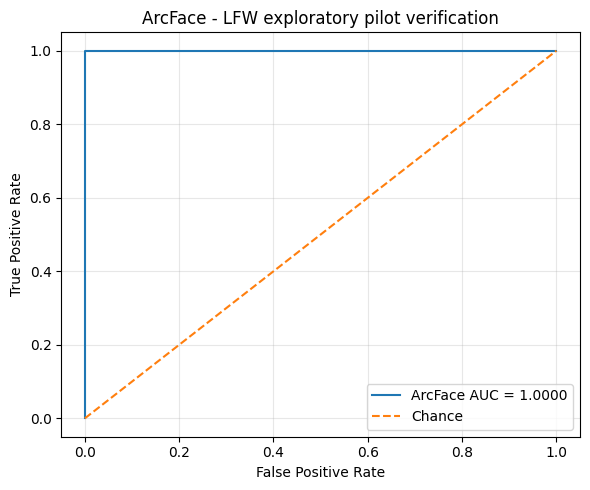

In [26]:
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'ArcFace AUC = {auc:.4f}')
plt.plot([0,1],[0,1],'--',label='Chance')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ArcFace - LFW exploratory pilot verification')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(GRAPH_DIR / 'arcface_pilot_roc.png', dpi=300, bbox_inches='tight')
plt.show()

In [27]:
summary = {
    'experiment':'ArcFace LFW exploratory pilot', 'model':'InsightFace buffalo_l',
    'dataset':'LFW subset, min 10 images per identity',
    'max_images_requested':MAX_IMAGES, 'images_selected':len(selected),
    'successful_embeddings':len(E), 'failed_detections':len(failed_indices),
    'positive_pairs':len(positive), 'negative_pairs':len(negative),
    'roc_auc':float(auc), 'approximate_eer':float(eer),
    'python_version':platform.python_version(), 'sklearn_version':sklearn.__version__,
    'evaluation_type':'Exploratory pilot; not official LFW protocol'
}
with open(RESULT_DIR / 'arcface_pilot_summary.json','w') as f:
    json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))

{
  "experiment": "ArcFace LFW exploratory pilot",
  "model": "InsightFace buffalo_l",
  "dataset": "LFW subset, min 10 images per identity",
  "max_images_requested": 500,
  "images_selected": 500,
  "successful_embeddings": 498,
  "failed_detections": 2,
  "positive_pairs": 548,
  "negative_pairs": 548,
  "roc_auc": 1.0,
  "approximate_eer": 0.0,
  "python_version": "3.13.15",
  "sklearn_version": "1.9.1",
  "evaluation_type": "Exploratory pilot; not official LFW protocol"
}
